In [1]:
#Problem Statement : A Hadamard gate creates an equal superposition of |0⟩ and |1⟩, producing a result 
#similar to a fair quantum coin. But can you control the measurement probabilities? Your task is to modify a 
#single-qubit circuit so that the measurement outcomes are not equally distributed.

In [3]:

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
import numpy as np

Circuit 1: P(1) = 20%


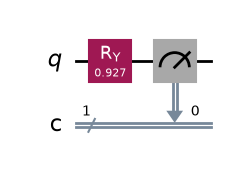

Circuit 2: P(1) = 50%


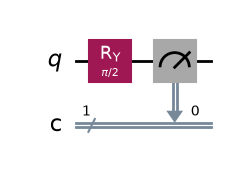

Circuit 3: P(1) = 80%


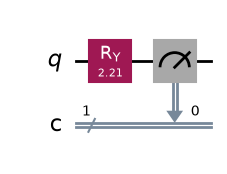

Circuit 1 results: {'1': 13, '0': 87}
Circuit 2 results: {'0': 54, '1': 46}
Circuit 3 results: {'1': 86, '0': 14}


In [5]:



# Choose different probabilities for measuring 1
probabilities = [0.2, 0.5, 0.8]

circuits = []

for p in probabilities:
    
    theta = 2 * np.arcsin(np.sqrt(p))

    # Create a single-qubit circuit
    qc = QuantumCircuit(1, 1)

    # Apply RY gate to create the desired bias
    qc.ry(theta, 0)

    # Measure the qubit
    qc.measure(0, 0)

    circuits.append(qc)

# Display the circuits
for i, qc in enumerate(circuits):
    print(f"Circuit {i+1}: P(1) = {probabilities[i]*100:.0f}%")
    display(qc.draw("mpl"))

# Execute all circuits for 100 shots
simulator = AerSimulator()
result = simulator.run(circuits, shots=100).result()

# Collect and print measurement counts
counts_list = []

for i in range(len(circuits)):
    counts = result.get_counts(i)
    counts_list.append(counts)
    print(f"Circuit {i+1} results:", counts)



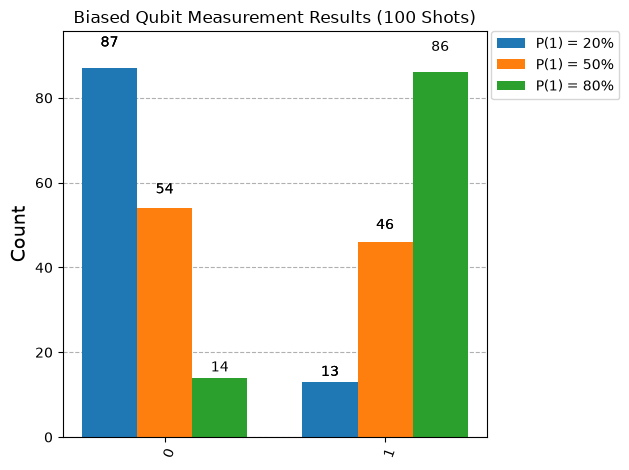

In [6]:
# Display histogram
fig = plot_histogram(
    counts_list,
    legend=["P(1) = 20%", "P(1) = 50%", "P(1) = 80%"],
    title="Biased Qubit Measurement Results (100 Shots)"
)

display(fig)


In [ ]:
#Challenge Question – 
#How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?

In [1]:
#Quantum gates change a qubit's quantum state, thereby changing the probabilities of 
#obtaining 0 or 1 when measured. For example, the X gate flips the qubit from \(|0\rangle\) 
#to \(|1\rangle\), while the Hadamard (H) gate creates an equal superposition, giving a 50% probability 
#of measuring either outcome. The RY gate rotates the qubit by a specified angle, allowing us to control 
#the measurement probabilities. Thus, by applying different quantum gates, we can create balanced or 
#biased measurement outcomes.